# 第 3 课｜职位文本分析与技能特征

**90 分钟：文本处理 20′ → 技能词典与关键词 30′ → 特征分析 30′ → 抽查 10′**

目标：把职责与要求变成可分析特征。使用可解释技能词典，并用 TF-IDF 探索额外关键词。
“文本提及”不等于“必须掌握”；没有提及也不代表不需要。先分开职责/要求，再分析合并文本。

In [1]:
from pathlib import Path
import sys, json, re
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# 支持从项目根目录、课程目录或 notebooks 目录启动。
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'course_utils.py').exists()), None)
if ROOT is None:
    ROOT = next((p / 'data_analysis202612' for p in candidates
                 if (p / 'data_analysis202612' / 'course_utils.py').exists()), None)
assert ROOT is not None, '请从项目根目录或课程目录启动 Jupyter'
sys.path.insert(0, str(ROOT))
from course_utils import *
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_rows', 20)
print('课程目录：', ROOT)
print('Python：', sys.version.split()[0])
print('解释器：', sys.executable)

课程目录： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612
Python： 3.10.16
解释器： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
import jieba
setup_plotting()
jobs = pd.read_parquet(DATA / 'processed' / 'jobs_clean.parquet')
jobs['analysis_text'] = jobs['description_clean'] + ' ' + jobs['requirement_clean']
jobs['text_length'] = jobs['analysis_text'].str.strip().str.len()
jobs['has_requirement'] = jobs['requirement_clean'].str.len().gt(0)
display(jobs[['title_clean', 'description_clean', 'requirement_clean']].sample(4, random_state=SEED))

,title_clean,description_clean,requirement_clean
13307,达人营销产品运营实习生-国际化,日常实习：面向全体在校生，为符合岗位要求的同学提供为期3个月及以上的项目实践机会。 团队介绍：国际化短视频商业化变现产品设...,1、本科及以上学历在读，统计、商业分析、广告、传播等相关专业优先； 2、英语流利，可作为工作语言； 3、有内容/创作者相关...
39543,任务策划实习生,1.你将设计贯穿游戏核心体验的任务流程， 让剧情、玩法互相融合； 2.搭建任务逻辑框架，平衡引导性、自由度和惊喜感，把控玩...,1.你对“好任务”有敏锐的直觉，能清晰分析为什么某个任务让你印象深刻（或倍感无聊）； 2.熟悉任一商业化引擎，了解相关脚本...
9163,大模型评测研究员（智能安全） - 安全与风控,"团队介绍：负责公司大模型信息安全保障体系，持续识别和治理大模型衍生出的新型风险，并建设相应安全产品,保障大模型及其应用在训...",1、对评测有激情，相信评测的重要性； 2、有大模型“和”安全领域相关的经验和意识，例如CTF/漏洞/逆向/模型训练/Age...
18699,AI安全蓝军高级工程师,1.负责公司核心业务与 AI 场景的安全评估和对抗演练，从安全研究视角发现真实风险，通过渗透测试、漏洞挖掘、风险验证和场景...,三年以上工作经验


## 1. 词典规则：边界、别名与误报

SQL 包含 MySQL/PostgreSQL 等明确别名；Java 不匹配 JavaScript；英语词前后使用字母数字边界。
这些都是可修改的规则。`沟通协作` 是宽泛提及，不适合当作可量化能力评分。
中文短语和英文词边界不同：`熟悉Python开发` 仍应命中 Python。

In [3]:
display(pd.DataFrame({'技能': list(SKILLS), '匹配规则': list(SKILLS.values())}))
examples = ['熟悉JavaScript和MySQL', '掌握JAVA与Python开发', 'NoSQL经验', '有机器学习和跨部门沟通经验']
display(pd.DataFrame([{'文本': x, **skill_hits(x)} for x in examples]))
assert skill_hits('JavaScript')['Java'] == 0
assert skill_hits('熟悉JAVA开发')['Java'] == 1
assert skill_hits('NoSQL')['SQL'] == 0
assert skill_hits('MySQL')['SQL'] == 1
assert skill_hits('CPython')['Python'] == 0
assert clean_text('<p>Python &amp; SQL</p>') == 'Python & SQL'

,技能,匹配规则
0,Python,(?<![a-z0-9_])python(?![a-z0-9_])
1,SQL,(?<![a-z0-9_])(?:sql|mysql|postgresql|postgres|sql\s*server|h...
2,Java,(?<![a-z0-9_])java(?![a-z0-9_])
3,JavaScript/TypeScript,(?<![a-z0-9_])(?:javascript|typescript)(?![a-z0-9_])
4,Excel,(?<![a-z0-9_])excel(?![a-z0-9_])
5,BI工具,(?<![a-z0-9_])(?:tableau|power\s*bi|superset)(?![a-z0-9_])|商业智能
6,Spark,(?<![a-z0-9_])(?:spark|pyspark)(?![a-z0-9_])
7,Hadoop/Hive,(?<![a-z0-9_])(?:hadoop|hive)(?![a-z0-9_])
8,机器学习,机器学习|machine\s+learning
9,深度学习,深度学习|deep\s+learning|(?<![a-z0-9_])(?:pytorch|tensorflow)(?![...


,文本,Python,SQL,Java,JavaScript/TypeScript,Excel,BI工具,...,A/B测试,统计分析,数据可视化,沟通协作,项目管理,用户研究,英语
0,熟悉JavaScript和MySQL,0,1,0,1,0,0,...,0,0,0,0,0,0,0
1,掌握JAVA与Python开发,1,0,1,0,0,0,...,0,0,0,0,0,0,0
2,NoSQL经验,0,0,0,0,0,0,...,0,0,0,0,0,0,0
3,有机器学习和跨部门沟通经验,0,0,0,0,0,0,...,0,0,0,1,0,0,0


In [4]:
requirements = pd.DataFrame(jobs['requirement_clean'].map(skill_hits).tolist(), index=jobs.index)
descriptions = pd.DataFrame(jobs['description_clean'].map(skill_hits).tolist(), index=jobs.index)
# 分别识别再取并集，避免两个字段拼接后产生原文并不存在的跨字段词组。
combined = requirements.combine(descriptions, np.maximum)
for skill in SKILLS:
    jobs['skill_' + skill] = combined[skill].astype('int8')
    jobs['req_' + skill] = requirements[skill].astype('int8')
    jobs['desc_' + skill] = descriptions[skill].astype('int8')
jobs['skill_count'] = combined.sum(axis=1)
jobs['experience_years_min'] = jobs['requirement_clean'].map(experience_min)
jobs['degree_text'] = jobs['requirement_clean'].map(degree_from_text)
assert experience_min('3-5年数据分析经验') == 3
assert np.isnan(experience_min('制定3年规划'))
assert np.isnan(experience_min('3年以下工作经验'))  # 上限不冒充最低年限
display(jobs[['title_clean', 'skill_Python', 'skill_SQL', 'skill_count', 'experience_years_min', 'degree_text']].head(10))

,title_clean,skill_Python,skill_SQL,skill_count,experience_years_min,degree_text
0,用户产品经理（造世界方向） - 抖音社交与互动,0,0,3,NaN,本科
1,游戏资深3D场景模型设计师 - 心光工作室,0,0,1,NaN,未抽取
2,游戏音乐设计师（PVE射击项目） - 研发支持中心,0,0,0,NaN,本科
3,芯片综合/STA工程师（存算与AI） - 芯片研发,1,0,4,NaN,硕士
4,东南亚跨境IP及主题活动运营-TikTok Shop,0,0,3,NaN,本科
5,交易链路产品经理-TikTok Shop,0,0,2,NaN,未抽取
6,亚太新兴市场TikTok广告增长运营负责人-Global Business Solutions,0,0,3,NaN,本科
7,机器学习研发工程师 - TikTok Search,0,0,4,NaN,未抽取
8,游戏分镜师（CCG卡牌） - ZERO36工作室,0,0,1,NaN,大专
9,Agent Network后端研发工程师-算力基础设施,0,0,1,NaN,本科


## 2. 全量样本中的技能提及率

给出两个口径：职责或要求提及数/全部职位；要求提及数/有要求文本的职位。
两个分母不同，不能把两列差值当作技能重要性的差值。空要求列不会被当作“不需要技能”。

,skill,mentioned_jobs,all_job_rate,requirement_mentions,requirement_rate,requirement_denominator
14,沟通协作,27011,0.664,24735,0.616,40186
10,大模型,11573,0.285,8490,0.211,40186
0,Python,9161,0.225,9006,0.224,40186
17,英语,5519,0.136,5227,0.130,40186
1,SQL,5394,0.133,5227,0.130,40186
2,Java,5126,0.126,5068,0.126,40186
8,机器学习,4432,0.109,3655,0.091,40186
9,深度学习,3867,0.095,3461,0.086,40186
15,项目管理,3678,0.090,3051,0.076,40186
12,统计分析,2475,0.061,2265,0.056,40186


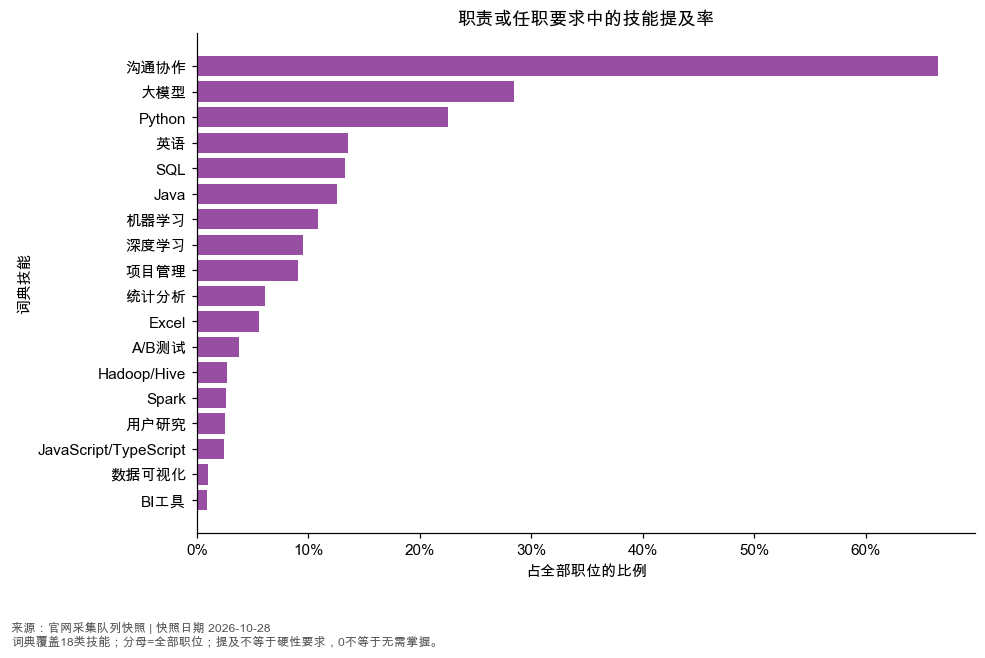

In [5]:
skills_summary = pd.DataFrame({
    'skill': list(SKILLS), 'mentioned_jobs': combined.sum().values,
    'all_job_rate': combined.mean().values,
    'requirement_mentions': requirements.sum().values,
    'requirement_rate': requirements.loc[jobs.has_requirement].mean().values,
    'requirement_denominator': int(jobs.has_requirement.sum()),
}).sort_values('all_job_rate', ascending=False)
display(skills_summary.round(3))
fig, ax = plt.subplots(figsize=(9, 6))
v = skills_summary.iloc[::-1]
ax.barh(v.skill, v.all_job_rate, color='#984ea3')
from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='职责或任职要求中的技能提及率', xlabel='占全部职位的比例', ylabel='词典技能')
save_figure(fig, '03_skill_mentions', '词典覆盖18类技能；分母=全部职位；提及不等于硬性要求，0不等于无需掌握。')
csv_export(skills_summary, '03_skill_mentions')

## 3. 聚焦数据相关岗位，比较公司与技能共现

先用标题正则筛选“数据分析/数据科学/数据挖掘/商业分析/商业智能”等候选，属于规则子集，
不是经过人工标注的完整岗位类别。对候选标题抽查后再解释结果。
跨公司对比只展示候选数≥20的公司，并保留各公司样本量。

,job_key,company_name,title_clean
30903,30904,快手,商业分析师（通用方向）-【商业化】
32944,32945,快手,数据分析实习生-社区治理
10551,10552,字节跳动,US大促数据科学实习生 - TikTok Shop
36956,36957,滴滴,IBG Food-商业分析实习生
12118,12119,字节跳动,数据科学 - 抖音增长
4046,4047,字节跳动,数据分析师-TikTok用户增长
18210,18211,腾讯,企业微信-数据分析师
2273,2274,字节跳动,风险数据分析专家 - 抖音社区治理
29579,29580,美团,中东商业分析实习生
9164,9165,字节跳动,体验运营（数据分析方向）-TikTok


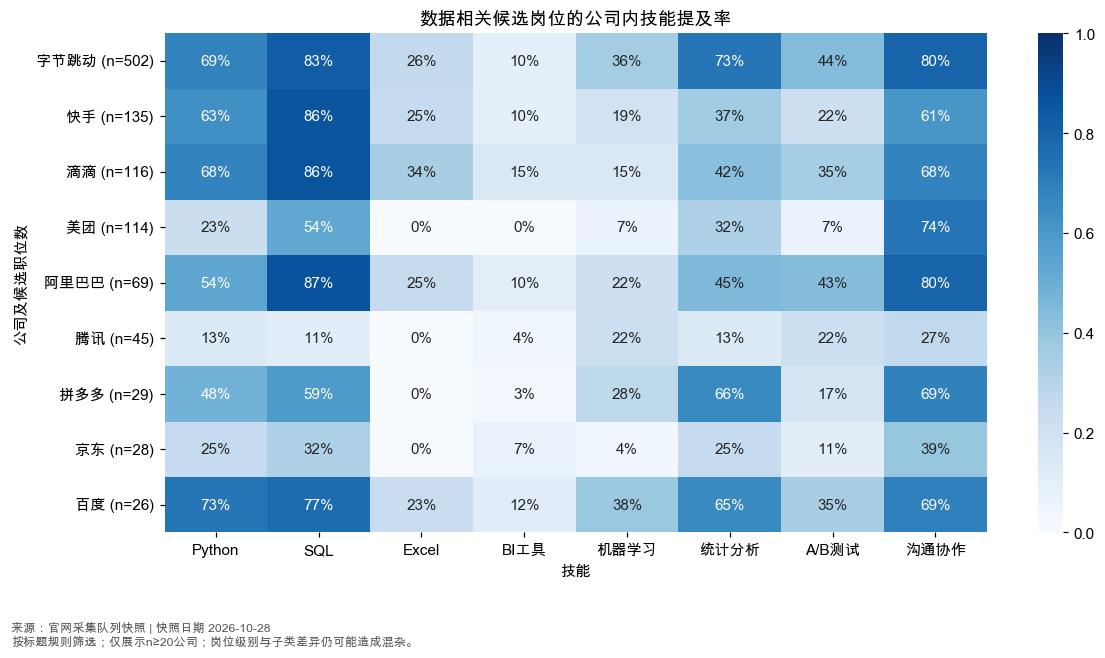

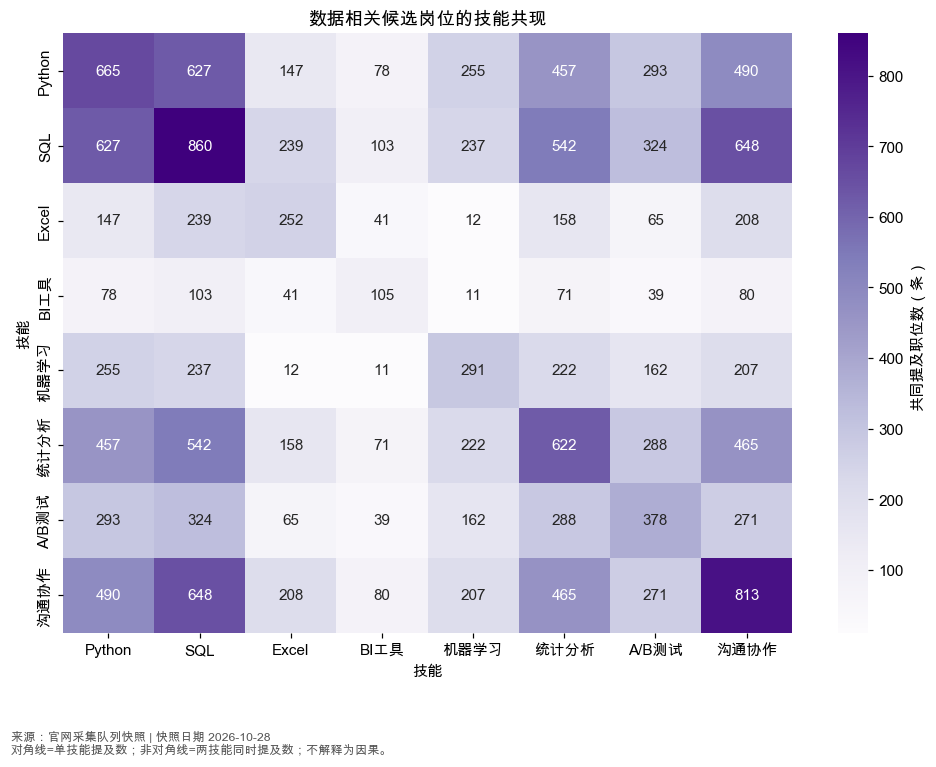

In [6]:
jobs['focus_candidate'] = jobs['title_clean'].str.contains(FOCUS_PATTERN, case=False, regex=True, na=False)
focus = jobs.loc[jobs.focus_candidate].copy()
assert len(focus) >= 50, '候选过少，请调整聚焦规则'
display(focus[['job_key', 'company_name', 'title_clean']].sample(min(12, len(focus)), random_state=SEED))
focus_counts = focus.groupby('company_name').size().rename('n')
skill_cols = ['skill_' + s for s in SKILLS]
company_skills = focus.groupby('company_name')[skill_cols].mean()
eligible = focus_counts[focus_counts.ge(20)].sort_values(ascending=False).index
chosen_skills = ['Python', 'SQL', 'Excel', 'BI工具', '机器学习', '统计分析', 'A/B测试', '沟通协作']
fig, ax = plt.subplots(figsize=(11, 6))
view = company_skills.loc[eligible, ['skill_' + s for s in chosen_skills]].copy()
view.columns = chosen_skills
view.index = [f'{name} (n={focus_counts[name]})' for name in view.index]
sns.heatmap(view, annot=True, fmt='.0%', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set(title='数据相关候选岗位的公司内技能提及率', xlabel='技能', ylabel='公司及候选职位数')
save_figure(fig, '03_focus_company_skills', '按标题规则筛选；仅展示n≥20公司；岗位级别与子类差异仍可能造成混杂。')
csv_export(company_skills.join(focus_counts).reset_index(), '03_focus_company_skills')

binary = focus[['skill_' + s for s in chosen_skills]].astype('int64')
cooccurrence = binary.T @ binary  # 必须转int64，避免int8矩阵乘法溢出
cooccurrence.index = chosen_skills
cooccurrence.columns = chosen_skills
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cooccurrence, annot=True, fmt='d', cmap='Purples', ax=ax, cbar_kws={'label': '共同提及职位数（条）'})
ax.set(title='数据相关候选岗位的技能共现', xlabel='技能', ylabel='技能')
save_figure(fig, '03_skill_cooccurrence', '对角线=单技能提及数；非对角线=两技能同时提及数；不解释为因果。')
csv_export(cooccurrence.reset_index(names='skill'), '03_skill_cooccurrence')
assert np.array_equal(np.diag(cooccurrence), binary.sum().values)

## 4. 用 TF-IDF 探索词典外关键词

TF：词在职位文本中的频率；IDF：在很多职位中都出现的词权重更低。
先分词与停用词过滤，再提取候选岗位的平均 TF-IDF Top词。
这是一种探索分数，不是提及率，也不是技能重要性的客观分数。

In [7]:
stopwords = set('我们 你们 他们 以及 相关 工作 岗位 职责 要求 负责 具有 能够 良好 优秀 熟悉 优先 能力 以上 进行 包括 公司 团队 业务 经验 具备 使用 参与 通过 方向 支持 完成 基于 对于 了解 掌握 任职 本科 硕士 学历 职位'.split())
for word in ['数据分析', '商业分析', '数据科学', '数据挖掘', '机器学习', '深度学习', '用户增长', '实验设计', '数据仓库']:
    jieba.add_word(word)

def tokenize(text):
    return [w for w in jieba.lcut(text.lower())
            if len(w.strip()) >= 2 and w not in stopwords
            and re.fullmatch(r'[a-z][a-z0-9_+#.-]*|[一-鿿]{2,}', w)]

vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, min_df=5, max_df=0.85, max_features=3000)
X = vectorizer.fit_transform(focus['analysis_text'])
keywords = pd.DataFrame({'term': vectorizer.get_feature_names_out(),
                         'mean_tfidf': np.asarray(X.mean(axis=0)).ravel()}).sort_values('mean_tfidf', ascending=False)
display(keywords.head(25))
csv_export(keywords, '03_tfidf_keywords')
print('候选职位×词项矩阵：', X.shape)

Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/3q/wv1kfqy544v7lnd3d_75mg3w0000gn/T/jieba.cache


Loading model cost 0.254 seconds.


Prefix dict has been built successfully.


,term,mean_tfidf
459,产品,0.054898
1338,数据分析,0.053015
1738,策略,0.050820
2141,问题,0.042934
15,ai,0.040585
...,...,...
1513,沟通,0.028523
2175,项目,0.028322
1644,电商,0.028086
1252,指标,0.027629


候选职位×词项矩阵： (1138, 2212)


## 5. 人工抽查：规则验证不等于准确率验证

自动边界断言只证明规则按预期执行。没有人工标签，就不能报告精确率/召回率。
下面为每个技能抽取最多3个命中片段，保存核验表。教师/学生填写 `human_label`（1/0）与备注。
若要估计召回率，还须随机抽取未命中样本人工判断，不能只审核正例。

经验年限仅处理明确阿拉伯数字表达；“3年以下”是上限，不生成最低年限。
学历提取也是启发式，不覆盖所有英文或“本科/硕士”等复杂写法。请检查样本再使用。

In [8]:
audit_rows = []
for name, pattern in SKILLS.items():
    matched = jobs.loc[jobs['skill_' + name].eq(1)]
    for row in matched.sample(min(3, len(matched)), random_state=SEED).itertuples():
        hit = re.search(pattern, row.analysis_text, re.I)
        audit_rows.append({'job_key': row.job_key, 'skill': name, 'title': row.title_clean,
                           'snippet': row.analysis_text[max(0, hit.start()-45):hit.end()+65],
                           'human_label': '', 'comment': ''})
audit = pd.DataFrame(audit_rows)
display(audit.head(12))
csv_export(audit, '03_skill_manual_audit')
# 对当前快照15条片段的教师参考审核；学生空白核验表另存，不被覆盖。
review = json.loads((ROOT / 'teacher_skill_review.json').read_text())
if review['snapshot_sha256'] == json.loads((DATA / 'raw' / 'manifest.json').read_text())['sha256']:
    teacher_review = audit.drop(columns=['human_label', 'comment']).merge(
        pd.DataFrame(review['rows']), on=['job_key', 'skill'], how='inner', validate='one_to_one')
    csv_export(teacher_review, '03_skill_teacher_review')
    display(teacher_review[['skill', 'snippet', 'human_label', 'comment']].head(6))
    print(review['scope'])
display(jobs.loc[jobs.experience_years_min.notna(), ['title_clean', 'requirement_clean', 'experience_years_min']].sample(
    min(8, jobs.experience_years_min.notna().sum()), random_state=SEED))

jobs.to_parquet(DATA / 'processed' / 'jobs_features.parquet', index=False)
write_json(REPORTS / 'text_metrics.json', {
    'focus_candidates': len(focus), 'all_jobs': len(jobs), 'skills': len(SKILLS),
    'with_requirement': int(jobs.has_requirement.sum()),
    'experience_extracted': int(jobs.experience_years_min.notna().sum()),
    'focus_python_rate': float(focus['skill_Python'].mean()),
    'focus_sql_rate': float(focus['skill_SQL'].mean()),
    'tfidf_features': X.shape[1], 'manual_audit_rows': len(audit),
})

,job_key,skill,title,snippet,human_label,comment
0,9767,Python,用户增长算法工程师-国际化短视频,提供增长动能。 1、具备强悍的编码能力和扎实的数据结构与算法功底，至少熟练掌握C/C++/python 等一种开发语言； ...,,
1,36758,Python,L Lab-算法实习生（2）,模型推理性能优化等大模型相关技术探索 （学历、目标院校、语言、技能、性格等要求） 1、熟悉python、java、c++等...,,
2,10192,Python,大语言模型算法实习生-Seed大模型人才实习,化、人工智能等相关专业优先； 2、优秀的代码能力、数据结构和基础算法功底，熟练C/C++或Python，ACM/ICPC、...,,
3,22789,SQL,阿里健康-数据开发-北京,位要求 1.3-5年以上数据研发经验； 2.技术基础扎实：熟练掌握java、python、sql中一种或多种数据处理语言等...,,
4,8047,SQL,印尼价格力策略运营-TikTok Shop,理、战略思维和策略分析能力，有经营分析、商业分析背景优先； 3、精通数据分析，能够熟练运用SQL、Python等工具进行深...,,
5,31342,SQL,质检运营专家（QA方向）,通过一定框架将问题归因清楚； 3、有优秀的数据敏感度和分析思维，能理解掌握业务指标逻辑，有SQL能力加分； 4、有较好的沟...,,
6,35694,Java,资深Java工程师-国际现金贷(北京上海杭州深圳),极与上下游团队沟通协作，推动项目落地。 1.统招本科及以上学历，计算机相关专业，3年及以上Java研发经验，扎实的编码及计...,,
7,7780,Java,AI研发效能工程师/架构师 - 计算,； 4、具备良好的工程实现能力，熟练掌握一门及以上开发语言（如Golang/Python/Java），能够独立推进系统或工...,,
8,40248,Java,CV算法工程师,学习和模式识别相关经验； 2、有一定的CV算法工作经验； 3、熟悉Linux系统，熟练使用Java/C++/Python其...,,
9,9328,JavaScript/TypeScript,AI原生安全智能体研发工程师-网络安全,以上相关研发经验（安全/网络/AI/Agent等方向）； 2、熟练掌握Go/Python/TypeScript中至少一门，...,,


,skill,snippet,human_label,comment
0,Python,提供增长动能。 1、具备强悍的编码能力和扎实的数据结构与算法功底，至少熟练掌握C/C++/python 等一种开发语言； ...,1,C/C++/Python等一种，属于可选语言集合，不是Python单项硬性要求
1,Python,模型推理性能优化等大模型相关技术探索 （学历、目标院校、语言、技能、性格等要求） 1、熟悉python、java、c++等...,1,python/java/c++的一种或多种，明确提及
2,Python,化、人工智能等相关专业优先； 2、优秀的代码能力、数据结构和基础算法功底，熟练C/C++或Python，ACM/ICPC、...,1,C/C++或Python，属于可选语言集合
3,SQL,位要求 1.3-5年以上数据研发经验； 2.技术基础扎实：熟练掌握java、python、sql中一种或多种数据处理语言等...,1,java/python/sql中一种或多种，明确提及
4,SQL,理、战略思维和策略分析能力，有经营分析、商业分析背景优先； 3、精通数据分析，能够熟练运用SQL、Python等工具进行深...,1,熟练运用SQL、Python，明确提及
5,SQL,通过一定框架将问题归因清楚； 3、有优秀的数据敏感度和分析思维，能理解掌握业务指标逻辑，有SQL能力加分； 4、有较好的沟...,1,有SQL能力加分，命中不应解释成硬性门槛


当前快照中15条命中片段的人工阅读；label=1仅确认该合并技能类别被提及，不代表必须要求；非盲评、非随机总体评估，不能据此估计精确率或召回率。


,title_clean,requirement_clean,experience_years_min
31538,廉正调查专家,1、5-10年以上相关工作经验（如反舞弊、合规、调查、廉洁从业、内审、稽查、监察、体制内公检法等），可以独立或带领团队完成...,5.0
6117,大模型产品经理-豆包,1、本科及以上学历，3年以上产品工作经验，有大语言模型、AI对话等产品经历优先； 2、了解LLM的技术原理和进展，熟悉海内...,3.0
36302,资深数据产品（开发方向）,1、3年以上数据产品工作经验，具有开发平台相关产品建设经验； 2、本科及以上学历，计算机/信息系统相关专业优先； 3、对H...,3.0
20007,全球速卖通事业部(AliExpress)-增长解决方案专家-杭州,1、本科及以上学历，国际物流、仓储相关专业。 2、3年以上相关工作经验，有互联网行业履约解决方案经验者优先。 3、具有敏锐...,3.0
31911,推荐算法工程师-【实时内容推荐】,1、计算机、数学或统计学相关专业，具备良好的逻辑思维能力、扎实的数据结构和算法功底，具备良好的沟通协作能力； 2、在互联网...,1.0
26319,公司金融岗,1.学历：统招本科及以上学历，法学、法律硕士（LLM/JD）或法律+财务/金融复合背景优先； 2.经验：5-10年工作经验...,5.0
22023,高德销服科技-美食交易-南区渠道经理-专项-广州,"1、5年以上相关行业经验，2年以上的团队管理经验； 2、熟悉本地生活，有O2O，互联网工作经验；对渠道, 生态管理等有比较...",5.0
33751,法务BP（广告商业化方向）,1、法学专业全日制本科及以上学历； 2、5年左右工作经验； 3、具有优秀的中英文书写能力和表达能力； 4、对品牌广告、效果...,5.0


## 课堂练习与验收

1. 新增“Git”技能，先写正例/反例，再统计；不要让 GitHub/GitLab 是否算别名成为隐含规则。
2. SQL 是硬性要求还是加分项？现有0/1列不能区分，尝试定位包含它的句子。
3. 完成核验表的10条人工判断，记录误报原因，修改词典并重新运行。
4. 比较职责提及率与要求提及率时，明确分母。不要把共现图称为因果关系。

**验收**：边界断言通过；共现对角线等于单技能计数；特征表可回溯 `job_key`；无虚构准确率。
输出：技能特征表、3 张图、关键词底稿、待人工标注核验表。